# Лабораторная 3. Логистическая регрессия

Maksim Kostromitin  
Group: J4132


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.titlesize": 12})
pd.set_option("display.float_format", "{:.4f}".format)

SEED = 42


## Данные

В данных 3 751 молекула и 1 776 признаков. Выделяем 75% данных в обучающую выборку и 25% в тестовую. Из обучающей части выделяем 20% в проверочную выборку для выбора шага обучения. Средние и масштабы признаков при стандартизации считаются только по обучающей части.


In [2]:
data = pd.read_csv("bioresponse.csv")
display(data.iloc[:5, :7].rename(columns={"Activity": "Отклик"}))

,Отклик,D1,D2,D3,D4,D5,D6
0,1,0.0000,0.4970,0.1000,0.0000,0.1330,0.6780
1,1,0.3667,0.6063,0.0500,0.0000,0.1112,0.8035
2,1,0.0333,0.4801,0.0000,0.0000,0.2098,0.6104
3,1,0.0000,0.5388,0.0000,0.5000,0.1963,0.7242
4,0,0.1000,0.5178,0.0000,0.0000,0.4947,0.7814


In [3]:
X = data.drop(columns="Activity").to_numpy(dtype=float)
y = data["Activity"].to_numpy(dtype=float)

train_ids, test_ids = train_test_split(
    np.arange(len(y)), test_size=0.25, stratify=y, random_state=SEED
)
fit_ids, val_ids = train_test_split(
    train_ids, test_size=0.20, stratify=y[train_ids], random_state=SEED
)

display(pd.DataFrame(
    [
        ["Обучающая выборка при подборе", len(fit_ids), y[fit_ids].mean()],
        ["Проверочная выборка", len(val_ids), y[val_ids].mean()],
        ["Обучающая выборка после подбора", len(train_ids), y[train_ids].mean()],
        ["Тестовая выборка", len(test_ids), y[test_ids].mean()],
    ],
    columns=["Часть", "Объекты", "Доля класса 1"],
))


,Часть,Объекты,Доля класса 1
0,Обучающая выборка при подборе,2250,0.5422
1,Проверочная выборка,563,0.5417
2,Обучающая выборка после подбора,2813,0.5421
3,Тестовая выборка,938,0.5426


In [4]:
scaler = StandardScaler().fit(X[fit_ids])
X_fit = np.asfortranarray(scaler.transform(X[fit_ids]).T)
X_val = np.asfortranarray(scaler.transform(X[val_ids]).T)
Y_fit = y[fit_ids][None, :]
Y_val = y[val_ids][None, :]


## Логистическая регрессия

Один столбец $X$ — одна молекула. Вероятность отклика равна $\sigma(w^T x+b)$; класс 1 выбирается при вероятности выше 0,5. Веса начинаются с нуля. Функция потерь — бинарная кросс-энтропия:

$$J=-\frac{1}{m}\sum_{i=1}^{m}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right].$$

В коде она вычисляется через `logaddexp`, чтобы избежать переполнения и логарифма нуля.


In [5]:
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z, dtype=float)))


def initialize_with_zeros(dim):
    return np.zeros((dim, 1)), 0.0


def propagate(w, b, X, Y):
    z = w.T @ X + b
    error = sigmoid(z) - Y
    cost = np.logaddexp(0, (1 - 2 * Y) * z).mean()
    grads = {"dw": X @ error.T / X.shape[1], "db": float(error.mean())}
    return grads, float(cost)

In [6]:
def predict(w, b, X, threshold=0.5):
    return (sigmoid(w.T @ X + b) > threshold).astype(int)


def evaluate(w, b, X, Y):
    z = w.T @ X + b
    loss = np.logaddexp(0, (1 - 2 * Y) * z).mean()
    accuracy = ((z > 0) == Y).mean()
    return float(loss), float(accuracy)

## Способы обновления весов

Обычный градиентный спуск (GD) обновляет веса по всей обучающей выборке. Стохастический градиентный спуск (SGD) обновляет их после каждой молекулы, перебирая данные в случайном порядке. Метод Adam использует порции по 64 объекта и подбирает масштаб шага для каждого веса по скользящим средним градиентов и их квадратов. Поправка на смещение учитывает, что эти средние начинаются с нуля.

Эпоха — один проход по обучающим данным. При подборе шага за эпоху GD делает 1 обновление, SGD — 2 250, Adam — 36. Сравниваем 200 проходов; число обновлений и время работы у методов разные.


In [7]:
def adam_step(gradient, mean, square_mean, step):
    mean = 0.9 * mean + (1 - 0.9) * gradient
    square_mean = 0.999 * square_mean + (1 - 0.999) * gradient**2
    corrected_mean = mean / (1 - 0.9**step)
    corrected_square = square_mean / (1 - 0.999**step)
    delta = corrected_mean / (np.sqrt(corrected_square) + 1e-8)
    return delta, mean, square_mean

In [8]:
def training_row(w, b, X, Y, X_val, Y_val, step):
    loss, accuracy = evaluate(w, b, X, Y)
    row = {"step": step, "train_loss": loss, "train_accuracy": accuracy}
    if X_val is not None:
        row["val_loss"], row["val_accuracy"] = evaluate(w, b, X_val, Y_val)
    return row

In [9]:
def optimize(
    w,
    b,
    X,
    Y,
    num_epochs,
    learning_rate,
    method="GD",
    batch_size=64,
    X_val=None,
    Y_val=None,
    seed=42,
):
    w = w.copy()
    rng = np.random.default_rng(seed)
    n = X.shape[1]
    size = {"GD": n, "SGD": 1, "Adam": batch_size}[method]
    mw, vw = np.zeros_like(w), np.zeros_like(w)
    mb, vb = 0.0, 0.0
    step = 0
    history = [training_row(w, b, X, Y, X_val, Y_val, step)]
    for _ in range(num_epochs):
        if method != "GD":
            order = rng.permutation(n)
        for start in range(0, n, size):
            batch = slice(None) if method == "GD" else order[start : start + size]
            grads, _ = propagate(w, b, X[:, batch], Y[:, batch])
            dw, db = grads["dw"], grads["db"]
            step += 1
            if method == "Adam":
                dw, mw, vw = adam_step(dw, mw, vw, step)
                db, mb, vb = adam_step(db, mb, vb, step)
            w -= learning_rate * dw
            b -= learning_rate * db
        history.append(training_row(w, b, X, Y, X_val, Y_val, step))
    return {"w": w, "b": b}, pd.DataFrame(history)


In [10]:
def model(
    X_train, Y_train, method, learning_rate, num_epochs, X_val=None, Y_val=None, seed=42
):
    w, b = initialize_with_zeros(X_train.shape[0])
    return optimize(
        w,
        b,
        X_train,
        Y_train,
        num_epochs,
        learning_rate,
        method,
        X_val=X_val,
        Y_val=Y_val,
        seed=seed,
    )


## Подбор шага обучения

Во всех запусках одинаковы разбиение, начальные веса и число эпох. Шаг выбирается по наибольшей доле верных ответов на проверочной выборке после 200 эпох, при равенстве — по меньшим потерям.


In [11]:
learning_rates = [0.0001, 0.001, 0.01, 0.1, 1.0]
num_epochs = 200
runs = {}

with threadpool_limits(limits=1):
    for method in ["GD", "SGD", "Adam"]:
        runs[method] = {}
        for rate in learning_rates:
            _, runs[method][rate] = model(
                X_fit, Y_fit, method, rate, num_epochs, X_val, Y_val, seed=SEED
            )


## Кривые обучения

По горизонтали — число обновлений весов. Потери на обучающей и проверочной выборках считаются после каждой эпохи по всем их объектам. В каждом столбце свой шаг обучения. Шкала потерь логарифмическая, диапазоны разные.

В таблице под графиками — доля верных ответов на проверочной выборке, %.


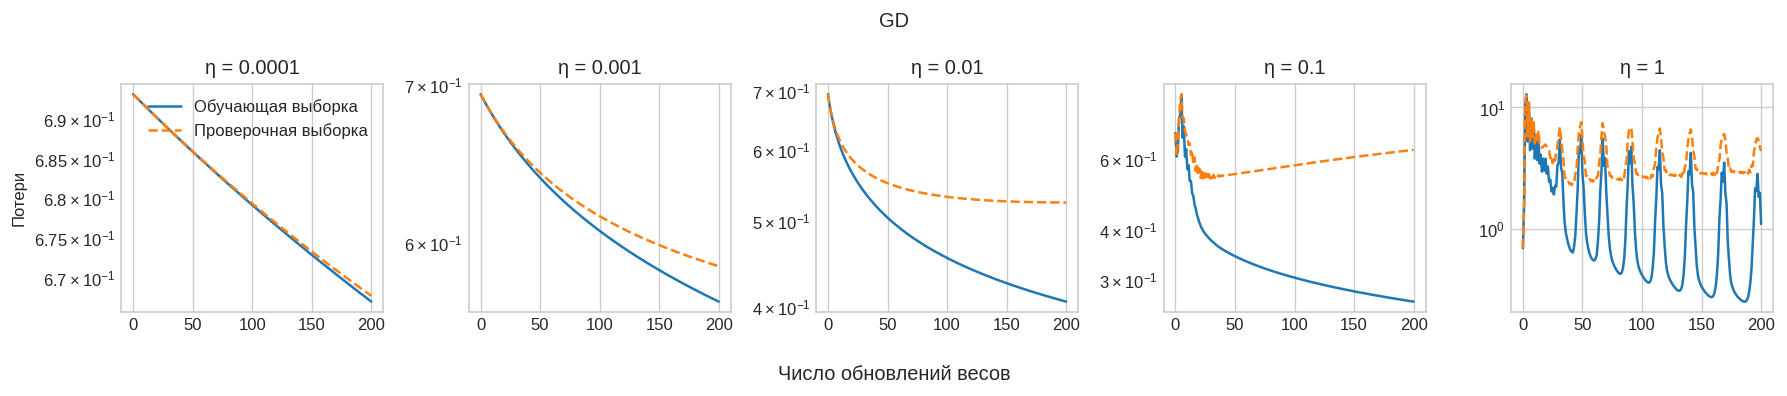

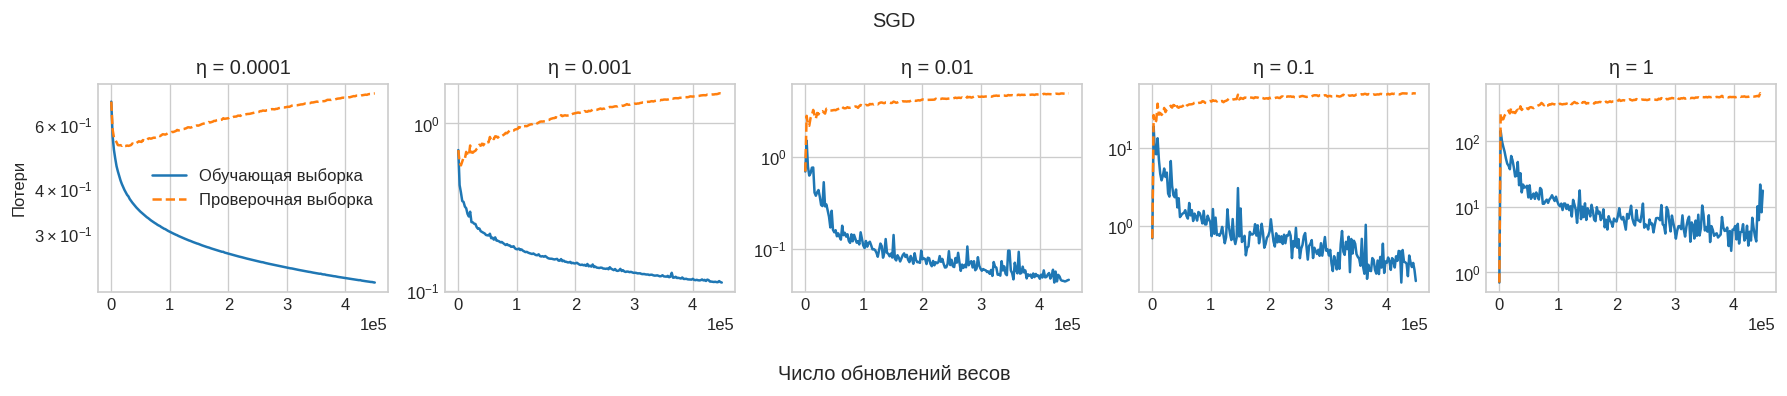

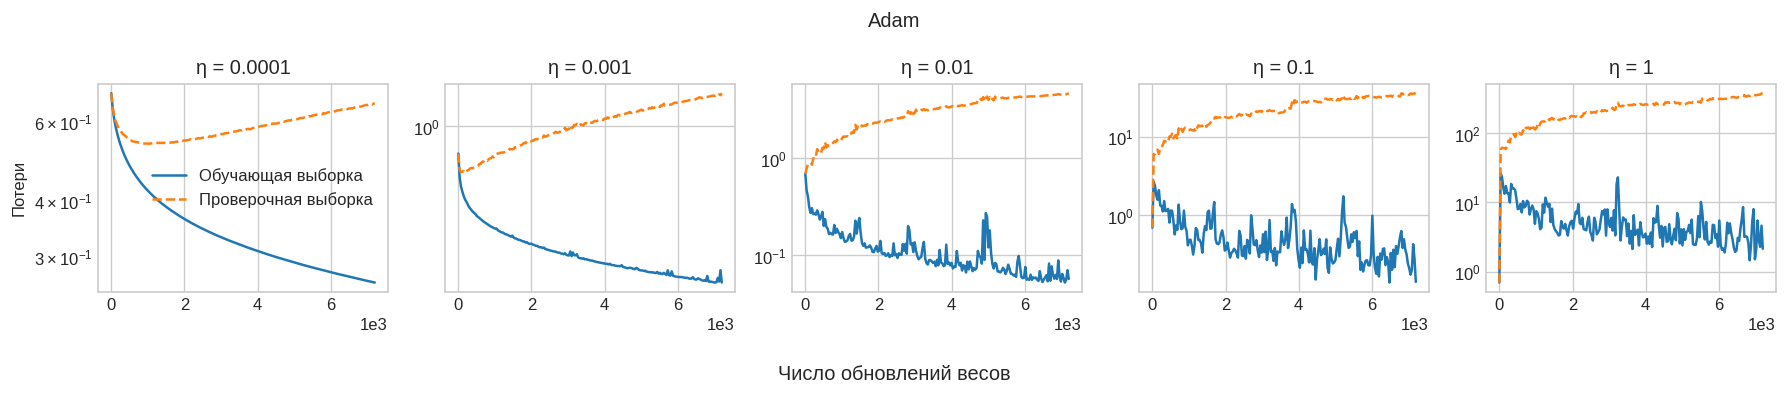

In [12]:
for method, histories in runs.items():
    fig, axes = plt.subplots(1, len(learning_rates), figsize=(15, 3.2), sharex=True)
    for ax, rate in zip(axes, learning_rates):
        h = histories[rate]
        ax.semilogy(h.step, h.train_loss, label="Обучающая выборка")
        ax.semilogy(h.step, h.val_loss, "--", label="Проверочная выборка")
        ax.set_title(f"η = {rate:g}")
        ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 3))
    axes[0].set_ylabel("Потери")
    axes[0].legend()
    fig.suptitle(method)
    fig.supxlabel("Число обновлений весов")
    fig.tight_layout()
    plt.show()


In [13]:
rows = []
for method, histories in runs.items():
    for rate, history in histories.items():
        row = history.iloc[-1].to_dict()
        row.update(method=method, learning_rate=rate)
        rows.append(row)
grid_table = pd.DataFrame(rows)
accuracy_by_rate = grid_table.pivot(
    index="learning_rate", columns="method", values="val_accuracy"
)
display((100 * accuracy_by_rate[["GD", "SGD", "Adam"]]).round(2)
        .rename_axis(index="Шаг обучения", columns="Метод"))


Метод,GD,SGD,Adam
Шаг обучения,,,
0.0001,68.9200,75.6700,73.8900
0.0010,73.3600,71.7600,73.5300
0.0100,75.6700,71.0500,70.5200
0.1000,74.2500,71.4000,70.5200
1.0000,70.8700,71.2300,71.5800


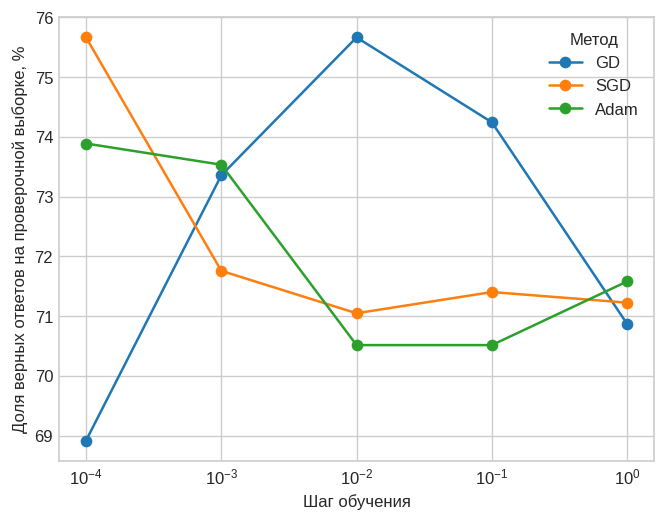

In [14]:
accuracy_by_rate[["GD", "SGD", "Adam"]].mul(100).plot(marker="o", logx=True)
plt.xlabel("Шаг обучения")
plt.ylabel("Доля верных ответов на проверочной выборке, %")
plt.legend(title="Метод")
plt.show()


### Влияние шага на результат

- Для GD лучший шаг — 0,01: 75,67% верных ответов. При шаге 0,0001 доля верных ответов составила 68,92%, при шаге 1 — 70,87%.
- Для SGD лучший шаг — 0,0001: 75,67% верных ответов. При остальных шагах — 71,05–71,76%.
- Для Adam лучший шаг тоже 0,0001: 73,89% верных ответов. При остальных шагах — 70,52–73,53%.

Малый шаг замедляет обучение GD. Большие шаги усиливают колебания потерь.


In [15]:
best_table = (
    grid_table.sort_values(
        ["val_accuracy", "val_loss", "learning_rate"], ascending=[False, True, True]
    )
    .drop_duplicates("method")
    .set_index("method")
    .loc[["GD", "SGD", "Adam"]]
)
best_rates = best_table["learning_rate"].to_dict()
display(
    best_table[["learning_rate", "val_accuracy", "val_loss"]].rename(
        columns={
            "learning_rate": "Выбранный шаг",
            "val_accuracy": "Доля верных ответов на проверочной выборке",
            "val_loss": "Потери на проверочной выборке",
        }
    ).rename_axis("Метод")
)

,Выбранный шаг,Доля верных ответов на проверочной выборке,Потери на проверочной выборке
Метод,,,
GD,0.0100,0.7567,0.5233
SGD,0.0001,0.7567,0.7304
Adam,0.0001,0.7389,0.6581


## Тестовая выборка

С выбранными шагами модели и стандартизатор заново обучаются на всех 2 813 обучающих объектах. Тестовая выборка содержит 938 молекул.

Дополнительно считаем ROC-AUC — площадь под кривой, которая сопоставляет долю верно найденных откликов и долю ложных срабатываний при разных порогах классификации.


In [16]:
final_scaler = StandardScaler().fit(X[train_ids])
X_train = np.asfortranarray(final_scaler.transform(X[train_ids]).T)
X_test = np.asfortranarray(final_scaler.transform(X[test_ids]).T)
Y_train = y[train_ids][None, :]
Y_test = y[test_ids][None, :]

majority_class = int(Y_train.mean() > 0.5)
baseline_accuracy = (Y_test == majority_class).mean()
display(
    pd.Series(
        {"Прогноз частого класса": baseline_accuracy}, name="Доля верных ответов на тестовой выборке"
    ).to_frame()
)

,Доля верных ответов на тестовой выборке
Прогноз частого класса,0.5426


In [17]:
final_rows = []
final_histories = {}
with threadpool_limits(limits=1):
    for method, rate in best_rates.items():
        params, history = model(X_train, Y_train, method, rate, num_epochs, seed=SEED)
        final_histories[method] = history
        w, b = params["w"], params["b"]
        loss, accuracy = evaluate(w, b, X_test, Y_test)
        probabilities = sigmoid(w.T @ X_test + b).ravel()
        final_rows.append(
            {
                "Метод": method,
                "Шаг": rate,
                "Accuracy train": history.train_accuracy.iloc[-1],
                "Accuracy test": accuracy,
                "Loss test": loss,
                "ROC-AUC test": roc_auc_score(Y_test.ravel(), probabilities),
            }
        )
display(pd.DataFrame(final_rows).set_index("Метод").round(4).rename(columns={
    "Accuracy train": "Доля верных ответов на обучающей выборке",
    "Accuracy test": "Доля верных ответов на тестовой выборке",
    "Loss test": "Потери на тестовой выборке",
    "ROC-AUC test": "ROC-AUC на тестовой выборке",
}))

,Шаг,Доля верных ответов на обучающей выборке,Доля верных ответов на тестовой выборке,Потери на тестовой выборке,ROC-AUC на тестовой выборке
Метод,,,,,
GD,0.0100,0.8187,0.7623,0.5256,0.8195
SGD,0.0001,0.9097,0.7655,0.6889,0.8105
Adam,0.0001,0.8919,0.7580,0.6176,0.8164


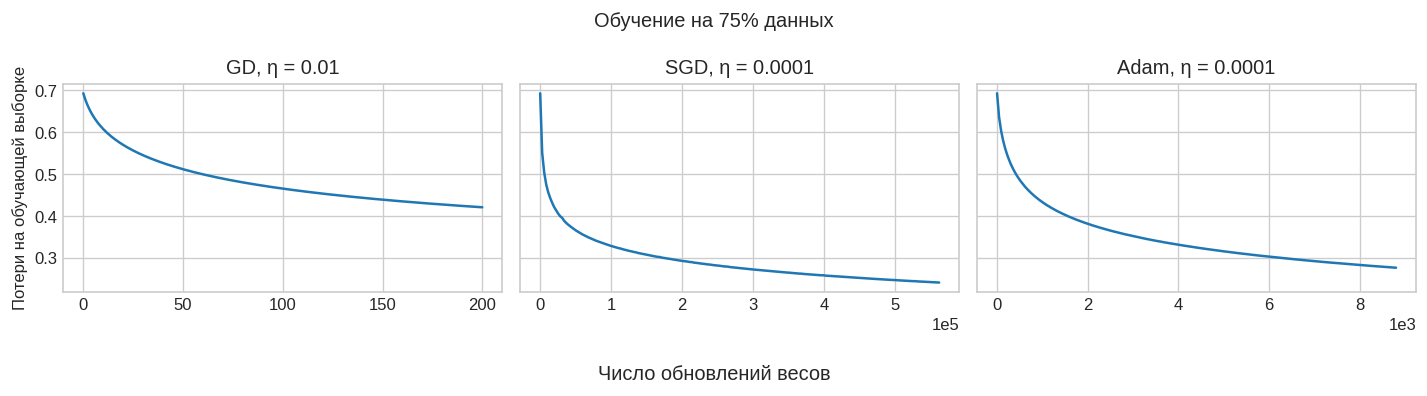

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (method, history) in zip(axes, final_histories.items()):
    ax.plot(history.step, history.train_loss)
    ax.set_title(f"{method}, η = {best_rates[method]:g}")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 3))
axes[0].set_ylabel("Потери на обучающей выборке")
fig.suptitle("Обучение на 75% данных")
fig.supxlabel("Число обновлений весов")
fig.tight_layout()
plt.show()


## Выводы

На тестовой выборке доля верных ответов у SGD составила 76,55%, у GD — 76,23%, у Adam — 75,80%. Разница небольшая, а самые низкие потери у GD. У SGD и Adam заметно переобучение: потери на обучающей выборке снижаются, а на проверочной растут.
